<a href="https://colab.research.google.com/github/trisadhiyanasywa-svg/Praktikum_MachineLearning/blob/TI08_Trisa_0110225049/Praktikum4_ML_Trisa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
df = pd.read_excel('/content/drive/MyDrive/ML 2026/Praktikum04/data/stunting_wasting_dataset.xlsx')
df.head()

,Jenis Kelamin,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting,Wasting
0,Laki-laki,19,91.6,13.3,Tall,Risk of Overweight
1,Laki-laki,20,77.7,8.5,Stunted,Underweight
2,Laki-laki,10,79.0,10.3,Normal,Risk of Overweight
3,Perempuan,2,50.3,8.3,Severely Stunted,Risk of Overweight
4,Perempuan,5,56.4,10.9,Severely Stunted,Risk of Overweight


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Jenis Kelamin      100000 non-null  object 
 1   Umur (bulan)       100000 non-null  int64  
 2   Tinggi Badan (cm)  100000 non-null  float64
 3   Berat Badan (kg)   100000 non-null  float64
 4   Stunting           100000 non-null  object 
 5   Wasting            100000 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 4.6+ MB


In [ ]:
df.isnull().sum()

,0
Jenis Kelamin,0
Umur (bulan),0
Tinggi Badan (cm),0
Berat Badan (kg),0
Stunting,0
Wasting,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Stunting'].unique()

array(['Tall', 'Stunted', 'Normal', 'Severely Stunted'], dtype=object)

In [ ]:
df['Jenis Kelamin'].unique()

array(['Laki-laki', 'Perempuan'], dtype=object)

In [ ]:
#1. Mapping kolom Stunting -> biner
map_stunt = {'Stunted': 1, 'Severely Stunted': 1, 'Normal': 0, 'Tall': 0}
df['Stunting_bin'] = df['Stunting'].map(map_stunt).astype('Int64')

# 2. Mapping kolom Jenis Kelamin -> biner
# Laki-Laki = 1, Perempuan = 0
df['JK_bin'] = (df['Jenis Kelamin'] == 'Laki-laki').astype(int)

print("Distribusi Stunting_bin: \n", df['Stunting_bin'].value_counts())
print("\nDistribusi JK_bin: \n", df['JK_bin'].value_counts())

Distribusi Stunting_bin: 
 Stunting_bin
0    72320
1    20372
Name: count, dtype: Int64

Distribusi JK_bin: 
 JK_bin
1    46353
0    46339
Name: count, dtype: int64


In [ ]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting_bin,JK_bin
Umur (bulan),1.000000,0.874162,0.659566,0.037173,0.000636
Tinggi Badan (cm),0.874162,1.000000,0.618453,-0.288216,0.070159
Berat Badan (kg),0.659566,0.618453,1.000000,0.020676,0.043446
Stunting_bin,0.037173,-0.288216,0.020676,1.000000,-0.005187
JK_bin,0.000636,0.070159,0.043446,-0.005187,1.000000


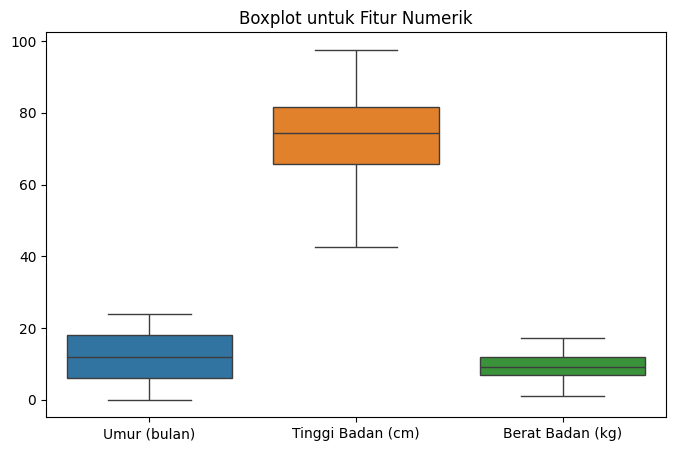

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(data=df[['Umur (bulan)', 'Tinggi Badan (cm)', 'Berat Badan (kg)']])
plt.title("Boxplot untuk Fitur Numerik")
plt.show()

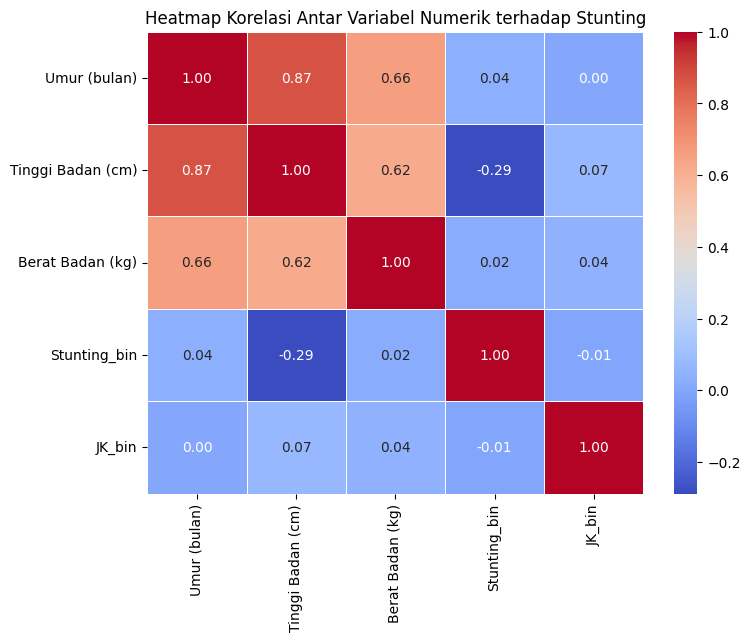

In [ ]:
# Visualisasi heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Variabel Numerik terhadap Stunting", fontsize=12)
plt.show()

In [ ]:
# Numerical and gender features
feature_num = ['Umur (bulan)', 'Tinggi Badan (cm)', 'Berat Badan (kg)']
feature_bin = ['JK_bin']

# Copy & drop missing
use_cols = feature_num + feature_bin + ['Stunting_bin']
df_model = df [use_cols].dropna().copy()

X = df_model [feature_num + feature_bin]
y = df_model ['Stunting_bin']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (92692, 4)
y shape: (92692,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (74153, 4)
Data uji: (18539, 4)


In [ ]:
# Scale numerical feature, gender passthrough
preprocess = ColumnTransformer(
    transformers=[
      ('num', StandardScaler(), feature_num),
       ('bin', 'passthrough', feature_bin)
],
    remainder='drop'
)

model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)

clf = Pipeline([
    ('preprocess', preprocess),
    ('model', model)
])

# Fit model
clf.fit(X_train, y_train)
print("Model Logistic Regression fit.")

Model Logistic Regression fit.


# PREDIKSI MODEL DAN EVALUASI MODEL

In [ ]:
# Prediction & Probabilities
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test) [:, 1]

# Metric Score
print(f"Akurasi : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob):.4f}")

Akurasi : 0.9063
Precision: 0.7139
Recall : 0.9571
F1-Score : 0.8178
ROC-AUC : 0.9651


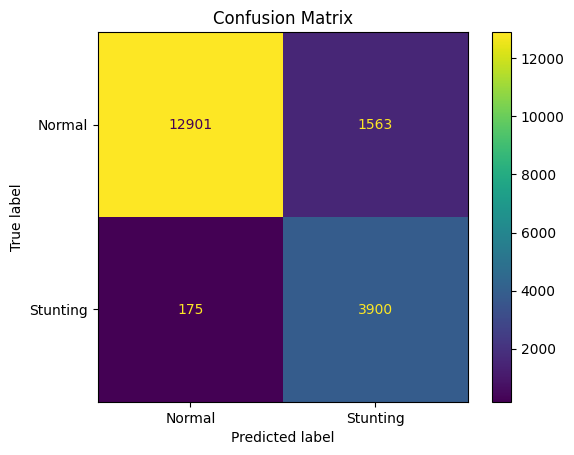

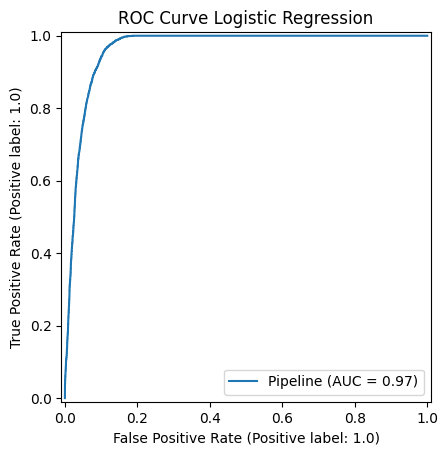

In [ ]:
# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['Normal', 'Stunting']
                       ).plot(values_format='d')

plt.title("Confusion Matrix")
plt.show()

# ROC Curve
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title("ROC Curve Logistic Regression")
plt.show()

In [ ]:
from sklearn.metrics import classification_report
print(classification_report (y_test, y_pred, target_names=['Tidak Stunting (0)', 'Stunting (1)']))

                    precision    recall  f1-score   support

Tidak Stunting (0)       0.99      0.89      0.94     14464
      Stunting (1)       0.71      0.96      0.82      4075

          accuracy                           0.91     18539
         macro avg       0.85      0.92      0.88     18539
      weighted avg       0.93      0.91      0.91     18539



In [ ]:
from sklearn.model_selection import cross_val_score

# Lakukan cross validation (cv=5 berarti 5-fold)
scores = cross_val_score(clf, X, y, cv=5)

# Validating scores
print("Score type fold:", scores)
print("Rata-rata average:", np.mean(scores))
print("Standard average:", np.std(scores))

Score type fold: [0.9084093  0.90414801 0.90468227 0.90673212 0.9028482 ]
Rata-rata average: 0.9053639814725255
Standard average: 0.001970695381359219


In [ ]:
# Ambil nama fitur & koefisien
feat_names = feature_num + feature_bin
coefs = clf.named_steps['model'].coef_[0]
odds = np.exp(coefs)

coef_df = pd.DataFrame({
    'Fitur': feat_names,
    'Koefisien (log-odds)': coefs,
    'Odds Ratio (e^coef)': odds
}).sort_values('Odds Ratio (e^coef)', ascending=False)

display(coef_df)

,Fitur,Koefisien (log-odds),Odds Ratio (e^coef)
0,Umur (bulan),8.661420,5775.733054
3,JK_bin,1.726339,5.620042
2,Berat Badan (kg),0.653153,1.921590
1,Tinggi Badan (cm),-10.742834,0.000022


In [ ]:
# Count 2 children
data_baru = pd.DataFrame({
    'Umur (bulan)': [24, 10],
    'Tinggi Badan (cm)': [79.0, 72.5],
    'Berat Badan (kg)': [9.2, 7.8],
    'JK_bin': [1, 0] # 1=Laki-laki, 0-Perempuan
})

pred = clf.predict(data_baru)
prob = clf.predict_proba(data_baru) [:,1]

hasil = data_baru.copy()
hasil['Prob_Stunting'] = prob
hasil['Pred (0=Tidak, 1=Ya)'] = pred

display(hasil)

,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),JK_bin,Prob_Stunting,"Pred (0=Tidak, 1=Ya)"
0,24,79.0,9.2,1,0.998346,1.0
1,10,72.5,7.8,0,0.001810,0.0


# PRAKTIKUM MANDIRI 4

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/ML 2026/Praktikum04/data/calonpembelimobil.csv', sep=',')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,1,32,1,0,0,240,1
1,2,49,2,1,1,100,0
2,3,52,1,0,2,250,1
3,4,26,2,1,1,130,0
4,5,45,3,0,2,237,1


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay)

# Read the CSV file with a comma delimiter
df = pd.read_csv('/content/drive/MyDrive/ML 2026/Praktikum04/data/calonpembelimobil.csv', sep=',')
df.head()

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,1,32,1,0,0,240,1
1,2,49,2,1,1,100,0
2,3,52,1,0,2,250,1
3,4,26,2,1,1,130,0
4,5,45,3,0,2,237,1


In [ ]:
df.info()
print("\nMissing value:\n", df.isnull().sum())
print("\nDuplikat:", df.duplicated().sum())
print("\nDistribusi target Beli_Mobil:\n", df['Beli_Mobil'].value_counts())
df[['Usia', 'Memiliki_Mobil', 'Penghasilan']].describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              1000 non-null   int64
 1   Usia            1000 non-null   int64
 2   Status          1000 non-null   int64
 3   Kelamin         1000 non-null   int64
 4   Memiliki_Mobil  1000 non-null   int64
 5   Penghasilan     1000 non-null   int64
 6   Beli_Mobil      1000 non-null   int64
dtypes: int64(7)
memory usage: 54.8 KB

Missing value:
 ID                0
Usia              0
Status            0
Kelamin           0
Memiliki_Mobil    0
Penghasilan       0
Beli_Mobil        0
dtype: int64

Duplikat: 0

Distribusi target Beli_Mobil:
 Beli_Mobil
1    633
0    367
Name: count, dtype: int64


,Usia,Memiliki_Mobil,Penghasilan
count,1000.00,1000.00,1000.00
mean,43.53,0.95,270.09
std,12.67,0.80,95.24
min,24.00,0.00,95.00
25%,33.00,0.00,187.00
50%,43.00,1.00,258.50
75%,53.00,2.00,352.25
max,164.00,4.00,490.00


In [ ]:
df = df.drop(columns=['ID'])

# Outlier usia (tidak masuk akal, > 100 tahun)
print(df[df['Usia'] > 100])
df = df[df['Usia'] <= 100].reset_index(drop=True)
print("Ukuran data setelah dibersihkan:", df.shape)

# Fitur & target
feature_num = ['Usia', 'Memiliki_Mobil', 'Penghasilan']
feature_cat = ['Status']      # kode 0-3 = kategori (nominal) -> One-Hot
feature_bin = ['Kelamin']     # 0/1 -> passthrough

X = df[feature_num + feature_cat + feature_bin]
y = df['Beli_Mobil']
print("X shape:", X.shape, "| y shape:", y.shape)

     Usia  Status  Kelamin  Memiliki_Mobil  Penghasilan  Beli_Mobil
200   164       0        0               0          100           0
227   131       2        1               0          100           0
Ukuran data setelah dibersihkan: (998, 6)
X shape: (998, 5) | y shape: (998,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), feature_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), feature_cat),
    ('bin', 'passthrough', feature_bin)
])

clf_mobil = Pipeline([
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
clf_mobil.fit(X_train, y_train)
print("Model Logistic Regression berhasil dilatih.")

Data latih: (798, 5) | Data uji: (200, 5)
Model Logistic Regression berhasil dilatih.


In [ ]:
y_pred = clf_mobil.predict(X_test)
y_prob = clf_mobil.predict_proba(X_test)[:, 1]

print(f"Akurasi   : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Tidak Beli (0)', 'Beli (1)']))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Akurasi   : 0.9350
Precision : 0.9672
Recall    : 0.9291
F1-Score  : 0.9478
ROC-AUC   : 0.9750

                precision    recall  f1-score   support

Tidak Beli (0)       0.88      0.95      0.91        73
      Beli (1)       0.97      0.93      0.95       127

      accuracy                           0.94       200
     macro avg       0.93      0.94      0.93       200
  weighted avg       0.94      0.94      0.94       200

Confusion Matrix:
 [[ 69   4]
 [  9 118]]


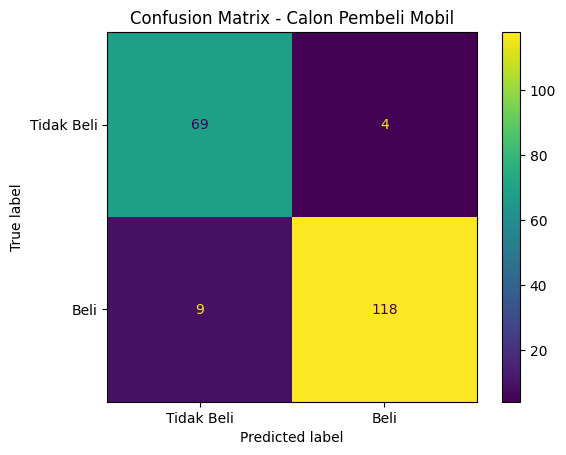

In [ ]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['Tidak Beli', 'Beli']).plot(values_format='d')
plt.title("Confusion Matrix - Calon Pembeli Mobil")
plt.show()

In [ ]:
data_baru = pd.DataFrame({
    'Usia':           [30, 45, 38, 55],
    'Status':         [1,  2,  3,  0],
    'Kelamin':        [0,  1,  0,  1],
    'Memiliki_Mobil': [0,  1,  2,  1],
    'Penghasilan':    [400, 120, 300, 200]
})

hasil = data_baru.copy()
hasil['Prob_Beli'] = clf_mobil.predict_proba(data_baru)[:, 1].round(4)
hasil['Pred (0=Tidak,1=Ya)'] = clf_mobil.predict(data_baru)
display(hasil)

,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Prob_Beli,"Pred (0=Tidak,1=Ya)"
0,30,1,0,0,400,1.0000,1
1,45,2,1,1,120,0.0019,0
2,38,3,0,2,300,0.9931,1
3,55,0,1,1,200,0.1796,0
